# 03 · Block 2 — scanlines

Goal: from the mask, find where the lines cross a band of rows — a list of blobs with sub-pixel positions.

Control needs two numbers, not a lane map. Reading one band of 6–8 rows is cheap, and averaging the rows suppresses noise.

In [2]:
%load_ext autoreload
%autoreload 2
import math
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, synthetic_drive, show, table, use_style
use_style()
from lanedet.mask import to_float, yellow_mask

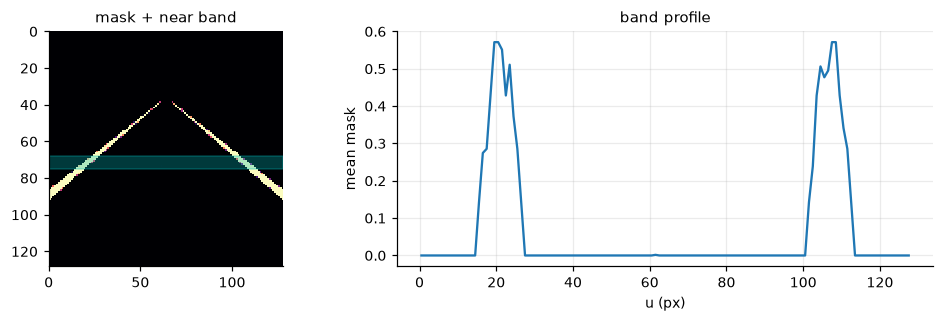

In [3]:
NEAR, FAR = (68, 75), (52, 58)  # placed by distance in 04
mask = yellow_mask(to_float(SyntheticTrack(noise=10).render(seed=0)))
profile = mask[NEAR[0]:NEAR[1]].mean(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [1, 1.7]})
ax[0].imshow(mask, cmap="magma", extent=(0, 128, 128, 0))
ax[0].axhspan(*NEAR, color="c", alpha=0.3)
ax[0].set_title("mask + near band")
ax[0].grid(False)
ax[1].plot(np.arange(128) + 0.5, profile)
ax[1].set(xlabel="u (px)", ylabel="mean mask", title="band profile")
plt.tight_layout()
plt.show()

## Design: locating lines in the profile

**A — split at the image centre**, centre of mass per half. Assumes one line per half.

**B — segment**: runs of the profile above a level are blobs; each blob's centroid is a line. No assumption about where the lines are.

Test both on a car yawed into a corner (far band): both lines move into the right half.

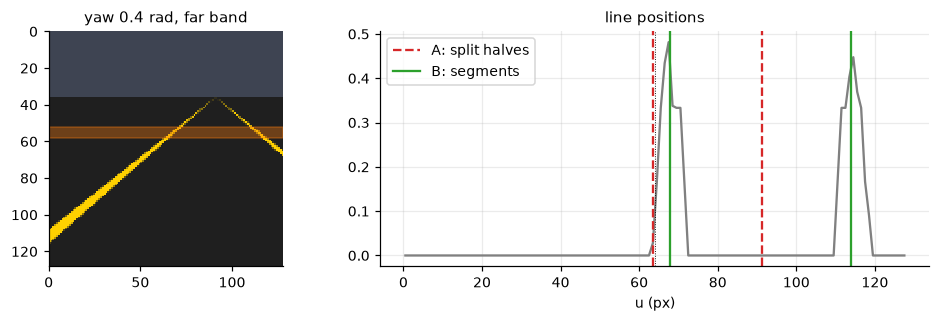

In [4]:
def option_a(profile):
    u, h = np.arange(len(profile)) + 0.5, len(profile) // 2
    return [(p * uu).sum() / (p.sum() + 1e-6) for p, uu in ((profile[:h], u[:h]), (profile[h:], u[h:]))]

def option_b(profile, level=0.1):
    on = np.concatenate([[False], profile > level, [False]])
    edges = np.flatnonzero(on[1:] != on[:-1])
    u = np.arange(len(profile)) + 0.5
    return [(profile[s:e] * u[s:e]).sum() / profile[s:e].sum() for s, e in zip(edges[::2], edges[1::2])]

yawed = SyntheticTrack(yaw=0.4).render()
p = yellow_mask(to_float(yawed))[FAR[0]:FAR[1]].mean(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [1, 1.7]})
ax[0].imshow(yawed, extent=(0, 128, 128, 0))
ax[0].axhspan(*FAR, color="tab:orange", alpha=0.35)
ax[0].set_title("yaw 0.4 rad, far band")
ax[0].grid(False)
ax[1].plot(np.arange(128) + 0.5, p, color="0.5")
ax[1].axvline(64, color="k", lw=0.6, ls=":")
for u in option_a(p):
    ax[1].axvline(u, color="tab:red", ls="--", label="A: split halves")
for u in option_b(p):
    ax[1].axvline(u, color="tab:green", label="B: segments")
handles = dict(zip(*ax[1].get_legend_handles_labels()[::-1]))
ax[1].legend(handles.values(), handles.keys())
ax[1].set(xlabel="u (px)", title="line positions")
plt.tight_layout()
plt.show()

A cuts the left line at the image centre: the sliver in the left half becomes "the left line", and the rest is averaged with the right line into u ≈ 91, where there is no paint. B finds both lines. Keep B, with a mass-weighted centroid inside each blob:

$$u = \frac{\sum_c (c + 0.5)\, p_c}{\sum_c p_c}$$

Each `Line` also carries its mass (≈ visible width in px) and a `clipped` flag when the blob touches the border — the line may continue out of view, biasing its centroid.

## Choosing the level

The level must sit below the weakest real line. It need not sit above the noise: noise specks are one pixel wide, so a minimum mass rejects them. Measure both over a noisy drive.

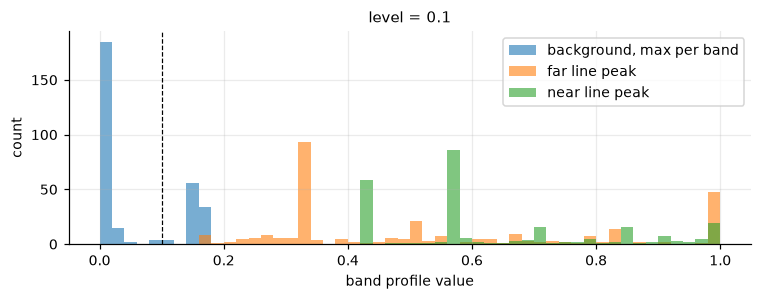

In [6]:
from helpers import synthetic_drive

near_pk, far_pk, bg_pk = [], [], []
for frame, tr in synthetic_drive(150, noise=12):
    m = yellow_mask(to_float(frame))
    for band, store in ((NEAR, near_pk), (FAR, far_pk)):
        p = m[band[0]:band[1]].mean(axis=0)
        z = tr.distance(sum(band) / 2)
        keep = np.ones(128, bool)
        for s in (-1, 1):
            u = int(64 + tr.focal * (tr.centre_x(z) + s * tr.half_width) / z)
            keep[max(0, u - 6):max(0, u + 7)] = False
            if 3 < u < 125:
                store.append(p[u - 2:u + 3].max())
        bg_pk.append(p[keep].max())

fig, ax = plt.subplots(figsize=(7, 2.8))
bins = np.linspace(0, 1, 51)
for data, label in ((bg_pk, "background, max per band"), (far_pk, "far line peak"), (near_pk, "near line peak")):
    ax.hist(data, bins, alpha=0.6, label=label)
ax.axvline(0.1, color="k", ls="--", lw=0.8)
ax.set(xlabel="band profile value", ylabel="count", title="level = 0.1")
ax.legend()
plt.tight_layout()
plt.show()

Far lines are thin and the band average smears slanted lines, so their peaks drop to ~0.17. Noise reaches the same height, but only as single-pixel specks with mass ≈ 0.17. Hence `level = 0.1` with `min_mass = 1.0`: every real line passes, mass removes the specks.

This cell saves the block to `lanedet/scan.py`. The next cell imports it.

In [5]:
%%writefile lanedet/scan.py
"""Block 2 - scanlines: collapse a band of rows to a 1D profile and find the line blobs in it."""

from dataclasses import dataclass

import numpy as np


@dataclass
class Line:
    u: float  # centroid, continuous pixel coordinate (pixel c spans [c, c+1))
    mass: float  # integrated profile, roughly the line width in pixels
    clipped: bool  # touches the image border, may be partly out of view


def band_profile(mask: np.ndarray, rows: tuple[int, int]) -> np.ndarray:
    """Mean of mask rows r0..r1-1 -> (W,) profile."""
    r0, r1 = rows
    return mask[r0:r1].mean(axis=0)


def find_lines(profile: np.ndarray, level: float = 0.1, min_mass: float = 1.0) -> list[Line]:
    """Runs of the profile above `level` -> one Line per run, left to right."""
    on = np.concatenate([[False], profile > level, [False]])
    edges = np.flatnonzero(on[1:] != on[:-1])
    lines = []
    for start, end in zip(edges[::2], edges[1::2]):
        p = profile[start:end]
        mass = float(p.sum())
        if mass < min_mass:
            continue
        u = float((p * (np.arange(start, end) + 0.5)).sum() / mass)
        lines.append(Line(u, mass, clipped=start == 0 or end == len(profile)))
    return lines

Writing lanedet/scan.py


In [6]:
from lanedet.scan import band_profile, find_lines

def true_line_u(track, v):
    z = track.distance(v)
    return [64 + track.focal * (track.centre_x(z) + s * track.half_width) / z for s in (-1, 1)]

rows = []
for name, tr in {
    "centred": SyntheticTrack(),
    "offset 0.1 m": SyntheticTrack(offset=0.1),
    "yaw 0.2": SyntheticTrack(yaw=0.2),
    "noise σ=15": SyntheticTrack(noise=15),
}.items():
    m = yellow_mask(to_float(tr.render(seed=0)))
    for band_name, band in (("near", NEAR), ("far", FAR)):
        lines = find_lines(band_profile(m, band))
        truth = [u for u in true_line_u(tr, sum(band) / 2) if 0 < u < 128]
        err = max(abs(l.u - t) for l, t in zip(lines, truth)) if len(lines) == len(truth) else float("nan")
        rows.append({"frame": name, "band": band_name, "found": len(lines), "in view": len(truth), "max error (px)": err})
table(rows)

frame,band,found,in view,max error (px)
centred,near,2,2,0.091
centred,far,2,2,0.068
offset 0.1 m,near,2,2,0.182
offset 0.1 m,far,2,2,0.344
yaw 0.2,near,2,2,0.103
yaw 0.2,far,2,2,0.109
noise σ=15,near,2,2,0.238
noise σ=15,far,2,2,0.072


Sub-pixel accuracy where the whole line is in view. Blobs cut by the border are flagged `clipped`.

## Check

In [7]:
for tr in (SyntheticTrack(), SyntheticTrack(offset=0.05, noise=12)):
    m = yellow_mask(to_float(tr.render(seed=3)))
    for band in (NEAR, FAR):
        lines = find_lines(band_profile(m, band))
        assert len(lines) == 2
        assert max(abs(l.u - t) for l, t in zip(lines, true_line_u(tr, sum(band) / 2))) < 0.3
assert find_lines(np.zeros(128)) == []
assert find_lines(np.r_[np.ones(3), np.zeros(125)])[0].clipped

## Exercises

1. Find an offset where option A fails on the near band.
2. Which `min_mass` rejects a single bright pixel of noise but keeps a far line?